# RQ3: CO₂ simulation with measured interval pressure

The 8–9 October record selects model factors; only the 9 and 10 October records form pooled evaluation. The unused fixed-pressure sensitivity analysis is excluded.

Saved results and plots are included for review. Regeneration requires CONTAM and EnergyPlus; see `DATA_NOTES.md`. No surrogate results replace a failed solver.

Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

In [1]:
from __future__ import annotations

import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
HERE = REPO_ROOT
from simulation.legacy_feasibility.physics import FANS, MMH2O_TO_PA
from simulation.measured_duty_pressure import (
    PRESSURE_MODES,
    measured_mean_pressure_pa,
    run_block,
    solver_room_pressure_pa,
    combined_intake_flow_m3h,
    one_intake_flow_m3h,
)

OUT = REPO_ROOT / "results/rq3_simulation"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)
(OUT / "text").mkdir(parents=True, exist_ok=True)

DATA = REPO_ROOT / "data/rq3"
SENSOR_LAG_S = 60.0
ENGINES = ["CO2_MASS_BALANCE", "CONTAM", "ENERGYPLUS"]
LABEL = {"CO2_MASS_BALANCE": "Mass-balance model", "CONTAM": "CONTAM", "ENERGYPLUS": "EnergyPlus"}
MODE_LABEL = {"fixed_4pa": "4 Pa", "measured_duty": "Recorded interval pressure"}
FAN_OFF_PHASES = {"qualification"}
EXPECTED_SHAPE = ["no ventilation", "ventilation", "no ventilation", "ventilation", "no ventilation", "ventilation"]
RECORDS = [
    {
        "name": "8–9 October 2026, 21:56-00:09",
        "solver_group": "20261008_215609",
        "path": DATA / "EXP_RQ3_CO2_RUN15_PHYS_20261008_215609/raw_runs/rep_1/rq2/EXP_RQ2_MATCHED_20261008_215609/rq2_matched_start.csv",
        "expected": [
            ("qualification", 525, 922),
            ("duty_100_percent", 921, 607),
            ("qualification", 603, 923),
            ("duty_80_percent", 925, 614),
            ("qualification", 611, 916),
            ("duty_60_percent", 918, 674),
        ],
    },
    {
        "name": "9 October 2026, 12:39-14:40",
        "solver_group": "20261009_123920",
        "path": DATA / "EXP_RQ3_CO2_RUN15_PHYS_20261009_123920/raw_runs/rep_1/rq2/EXP_RQ2_MATCHED_20261009_123921/rq2_matched_start.csv",
        "expected": [
            ("qualification", 619, 923),
            ("duty_100_percent", 925, 652),
            ("qualification", 649, 917),
            ("duty_80_percent", 919, 655),
            ("qualification", 655, 915),
            ("duty_60_percent", 916, 683),
        ],
    },
    {
        "name": "10 October 2026, 14:12-16:06",
        "solver_group": "20261010_141227",
        "path": DATA / "EXP_RQ3_CO2_RUN15_PHYS_20261010_141227/raw_runs/rep_1/rq2/EXP_RQ2_MATCHED_20261010_141227/rq2_matched_start.csv",
        "expected": [
            ("qualification", 609, 923),
            ("duty_100_percent", 921, 635),
            ("qualification", 631, 923),
            ("duty_80_percent", 925, 658),
            ("qualification", 653, 929),
            ("duty_60_percent", 928, 686),
        ],
    },
]


def sensor_lag(room_ppm, t_min, tau_s: float = SENSOR_LAG_S):
    room = np.asarray(room_ppm, dtype=float)
    times = np.asarray(t_min, dtype=float)
    reading = np.empty_like(room)
    if len(room) == 0:
        return reading
    reading[0] = room[0]
    for i in range(1, len(room)):
        if not np.isfinite(room[i]) or not np.isfinite(reading[i - 1]):
            reading[i] = room[i]
            continue
        dt_s = max(0.0, float(times[i] - times[i - 1]) * 60.0)
        decay = math.exp(-dt_s / tau_s) if tau_s > 0 else 0.0
        reading[i] = room[i] + (reading[i - 1] - room[i]) * decay
    return reading


def error_metrics(modelled, observed):
    error = np.asarray(modelled, dtype=float) - np.asarray(observed, dtype=float)
    return {
        "n": int(len(error)),
        "mae_ppm": float(np.mean(np.abs(error))),
        "rmse_ppm": float(np.sqrt(np.mean(error ** 2))),
        "bias_ppm": float(np.mean(error)),
        "final_error_ppm": float(error[-1]),
    }


def load_record(path: Path) -> dict:
    raw = pd.read_csv(path).sort_values("sample_time").reset_index(drop=True)
    raw["timestamp"] = pd.to_datetime(raw["sample_time"], utc=True, format="mixed")
    origin = raw["timestamp"].iloc[0]
    raw["t_min"] = (raw["timestamp"] - origin).dt.total_seconds() / 60.0
    raw["block_id"] = (
        raw["trial"].astype(str) + "|" + raw["phase"].astype(str)
    ).ne((raw["trial"].astype(str) + "|" + raw["phase"].astype(str)).shift()).cumsum()
    blocks = []
    for block_id, group in raw.groupby("block_id", sort=True):
        phase = str(group["phase"].iloc[0])
        if group["delta_pressure"].isna().any():
            raise RuntimeError(f"{path.name} {phase} has missing pressure")
        measured_dp = measured_mean_pressure_pa(group["delta_pressure"])
        for column in ("fan_exh_rpm", "fan_in1_rpm", "fan_in2_rpm"):
            if group[column].isna().any() or not np.isfinite(group[column].to_numpy(dtype=float)).all():
                raise RuntimeError(f"{path.name} {phase} has missing {column}")
        rpm_in1 = float(group["fan_in1_rpm"].mean())
        rpm_in2 = float(group["fan_in2_rpm"].mean())
        rpm_exh = float(group["fan_exh_rpm"].mean())
        blocks.append({
            "block_id": int(block_id),
            "phase": phase,
            "duty_percent": int(group["duty"].iloc[0]),
            "regime": "no ventilation" if phase.lower() in FAN_OFF_PHASES else "ventilation",
            "n": int(len(group)),
            "t0_min": float(group["t_min"].iloc[0]),
            "t1_min": float(group["t_min"].iloc[-1]),
            "duration_min": float(group["t_min"].iloc[-1] - group["t_min"].iloc[0]),
            "rpm": (rpm_in1 + rpm_in2) / 2.0,
            "rpm_in1": rpm_in1,
            "rpm_in2": rpm_in2,
            "rpm_exh": rpm_exh,
            "measured_dp_pa": measured_dp,
            "outdoor_ppm": float(group["co2_outdoor_ppm"].mean()),
            "physical_start_ppm": float(group["co2_indoor_ppm"].iloc[0]),
            "physical_end_ppm": float(group["co2_indoor_ppm"].iloc[-1]),
            "local_t_min": (group["t_min"] - float(group["t_min"].iloc[0])).to_numpy(dtype=float),
            "physical_ppm": group["co2_indoor_ppm"].to_numpy(dtype=float),
            "pressure_4pa": solver_room_pressure_pa((rpm_in1 + rpm_in2) / 2.0, measured_dp, "fixed_4pa"),
            "pressure_measured_pa": solver_room_pressure_pa((rpm_in1 + rpm_in2) / 2.0, measured_dp, "measured_duty"),
        })
    return {"raw": raw, "blocks": blocks, "path": path}


def score_record(spec: dict, mode: str, factors: dict) -> dict:
    loaded = load_record(spec["path"])
    raw = loaded["raw"]
    regimes = [block["regime"] for block in loaded["blocks"]]
    if regimes != EXPECTED_SHAPE:
        raise RuntimeError(f"{spec['name']} sections are {regimes}")
    if expected := spec["expected"]:
        for block, (phase, start, end) in zip(loaded["blocks"], expected):
            if block["phase"] != phase or abs(block["physical_start_ppm"] - start) > 2 or abs(block["physical_end_ppm"] - end) > 2:
                raise RuntimeError(f"{spec['name']} block {block['phase']} does not match the stored record")
    duty_rows = []
    for block in loaded["blocks"]:
        if block["regime"] != "ventilation":
            continue
        for engine in ENGINES:
            work = OUT / "solver_runs" / mode / spec["solver_group"] / "duty" / engine / f"block_{block['block_id']:02d}"
            result = run_block(engine, factors[engine], block, block["physical_start_ppm"], work, mode)
            row = {
                "record": spec["name"],
                "pressure_mode": mode,
                "scope": "duty-cycle interval",
                "duty_percent": block["duty_percent"],
                "engine": engine,
                "ventilation_effectiveness_factor": factors[engine],
                "room_pressure_pa": result["room_pressure_pa"],
                "intake_flow_m3h": result["intake_flow_m3h"],
                "status": "COMPLETED" if result["ok"] else "FAILED",
            }
            if not result["ok"]:
                raise RuntimeError(f"{spec['name']} {mode} {engine} duty {block['duty_percent']} failed: {result['notes']}")
            lagged = sensor_lag(result["co2_ppm"], block["local_t_min"])
            row.update(error_metrics(lagged, block["physical_ppm"]))
            duty_rows.append(row)
            print(f"{spec['name']} {MODE_LABEL[mode]} duty {block['duty_percent']} {LABEL[engine]} MAE {row['mae_ppm']:.2f}", flush=True)
    predicted = {engine: np.full(len(raw), np.nan) for engine in ENGINES}
    state = {engine: float(raw["co2_indoor_ppm"].iloc[0]) for engine in ENGINES}
    for block in loaded["blocks"]:
        for engine in ENGINES:
            work = OUT / "solver_runs" / mode / spec["solver_group"] / "whole" / engine / f"block_{block['block_id']:02d}"
            result = run_block(engine, factors[engine], block, state[engine], work, mode)
            if not result["ok"]:
                raise RuntimeError(f"{spec['name']} {mode} {engine} block {block['block_id']} failed: {result['notes']}")
            predicted[engine][raw["block_id"] == block["block_id"]] = result["co2_ppm"]
            state[engine] = float(result["co2_ppm"][-1])
    for engine in ENGINES:
        predicted[engine] = sensor_lag(predicted[engine], raw["t_min"].to_numpy(dtype=float))
    whole_rows = []
    regime = np.where(raw["phase"].str.lower().isin(FAN_OFF_PHASES), "no ventilation", "ventilation")
    scopes = [
        ("full record", np.ones(len(raw), dtype=bool)),
        ("ventilation", regime == "ventilation"),
        ("no ventilation", regime == "no ventilation"),
    ]
    for scope, mask in scopes:
        observed = raw.loc[mask, "co2_indoor_ppm"].to_numpy(dtype=float)
        for engine in ENGINES:
            whole_rows.append({
                "record": spec["name"],
                "pressure_mode": mode,
                "scope": scope,
                "duty_percent": None,
                "engine": engine,
                "ventilation_effectiveness_factor": factors[engine],
                **error_metrics(predicted[engine][mask], observed),
            })
    loaded["predicted"] = predicted
    return {"record": loaded, "summary": pd.DataFrame(whole_rows), "duty": pd.DataFrame(duty_rows)}


pressure_rows = []
for spec in RECORDS:
    loaded = load_record(spec["path"])
    for block in loaded["blocks"]:
        if block["regime"] != "ventilation":
            continue
        pressure_rows.append({
            "record": spec["name"],
            "duty_percent": block["duty_percent"],
            "rpm_in1_mean": block["rpm_in1"],
            "rpm_in2_mean": block["rpm_in2"],
            "rpm_exh_mean": block["rpm_exh"],
            "measured_mean_pa": block["measured_dp_pa"],
            "solver_pressure_4pa": block["pressure_4pa"],
            "solver_pressure_measured_pa": block["pressure_measured_pa"],
            "flow_in1_measured_m3h": one_intake_flow_m3h(block["rpm_in1"], block["pressure_measured_pa"]),
            "flow_in2_measured_m3h": one_intake_flow_m3h(block["rpm_in2"], block["pressure_measured_pa"]),
            "intake_flow_4pa_m3h": combined_intake_flow_m3h(block["rpm_in1"], block["rpm_in2"], block["pressure_4pa"]),
            "intake_flow_measured_m3h": combined_intake_flow_m3h(block["rpm_in1"], block["rpm_in2"], block["pressure_measured_pa"]),
        })
pressure_table = pd.DataFrame(pressure_rows)
pressure_table["intake_flow_change_m3h"] = pressure_table["intake_flow_measured_m3h"] - pressure_table["intake_flow_4pa_m3h"]
pressure_table.to_csv(OUT / "tables" / "duty_pressure_and_airflow.csv", index=False)
display(pressure_table.round(2))

def select_factors(mode: str):
    if mode == "fixed_4pa":
        pressure_sentence = "Each fan-on interval uses 4 Pa."
    elif mode == "measured_duty":
        pressure_sentence = "Each fan-on interval uses the mean measured room pressure of that duty."
    else:
        raise ValueError(mode)
    search_rows = []
    for engine in ENGINES:
        for eta in ETA_CANDIDATES:
            window_errors = []
            failed = False
            per_duty = {}
            notes = []
            for block in fit_blocks:
                work = OUT / "solver_runs" / f"{mode}_fit" / engine / f"eta_{eta:.2f}".replace(".", "p") / f"block_{block['block_id']:02d}"
                result = run_block(engine, eta, block, block["physical_start_ppm"], work, mode)
                if not result["ok"]:
                    failed = True
                    notes = result["notes"]
                    per_duty[block["duty_percent"]] = None
                    continue
                lagged = sensor_lag(result["co2_ppm"], block["local_t_min"])
                error = lagged - block["physical_ppm"]
                window_errors.append(error)
                per_duty[block["duty_percent"]] = float(np.mean(np.abs(error)))
            if failed or not window_errors:
                pooled = None
                status = "FAILED"
            else:
                pooled = float(np.mean(np.abs(np.concatenate(window_errors))))
                status = "COMPLETED"
            search_rows.append({
                "engine": engine,
                "eta": eta,
                "status": status,
                "mae_ppm": pooled,
                "mae_duty_100_ppm": per_duty.get(100),
                "mae_duty_80_ppm": per_duty.get(80),
                "mae_duty_60_ppm": per_duty.get(60),
                "notes": "" if status == "COMPLETED" else " | ".join(notes),
            })
    search_frame = pd.DataFrame(search_rows)
    search_frame.to_csv(OUT / "tables" / f"eta_search_{mode}_8oct.csv", index=False)
    chosen = {}
    for engine in ENGINES:
        completed = search_frame[(search_frame["engine"] == engine) & (search_frame["status"] == "COMPLETED")].sort_values(["mae_ppm", "eta"])
        if completed.empty:
            raise RuntimeError(f"No completed factor for {engine} under {mode}.")
        best = completed.iloc[0]
        nxt = completed.iloc[1] if len(completed) > 1 else None
        chosen[engine] = {
            "ventilation_effectiveness_factor": float(best["eta"]),
            "fit_mae_ppm": float(best["mae_ppm"]),
            "fit_mae_duty_100_ppm": float(best["mae_duty_100_ppm"]),
            "fit_mae_duty_80_ppm": float(best["mae_duty_80_ppm"]),
            "fit_mae_duty_60_ppm": float(best["mae_duty_60_ppm"]),
            "next_eta": None if nxt is None else float(nxt["eta"]),
            "next_mae_ppm": None if nxt is None else float(nxt["mae_ppm"]),
            "at_search_boundary": bool(float(best["eta"]) in (ETA_CANDIDATES[0], ETA_CANDIDATES[-1])),
        }
    factors = {engine: float(chosen[engine]["ventilation_effectiveness_factor"]) for engine in ENGINES}
    document = {
        "fit_record": fit_spec["name"],
        "fit_objective": (
            "Minimum mean absolute error on the three fan-on intervals of the 8 October 2026 collection "
            "(21:56 to 00:09). "
            + pressure_sentence
            + " Each intake fan is evaluated at its own mean recorded speed on the datasheet curve, and the two airflow estimates are added. "
            "Each interval starts at the measured indoor CO2 and is passed through a 60 s first-order SCD41 lag. "
            "The leakage opening is 0 mm. Fan-off intervals and the 9 October and 10 October collections are excluded from the selection."
        ),
        "sensor_lag_s": SENSOR_LAG_S,
        "pressure_mode": mode,
        "intake_airflow": "sum of datasheet operating points at the mean fan_in1_rpm and fan_in2_rpm",
        "fan_off_excluded": True,
        "leakage_m3h": 0.0,
        "generation_lps": 0.00317,
        "body_mass_kg": 58.0,
        "volume_m3": 18.0,
        "candidate_factors": ETA_CANDIDATES,
        "engines": chosen,
    }
    (OUT / f"frozen_ventilation_effectiveness_{mode}.json").write_text(json.dumps(document, indent=2), encoding="utf-8")
    table = pd.DataFrame([{"engine": engine, "label": LABEL[engine], **values} for engine, values in chosen.items()])
    print(f"Selected ventilation-effectiveness factors for {MODE_LABEL[mode]}.")
    display(table.round(3))
    return factors, search_frame, chosen


ETA_CANDIDATES = [round(float(value), 2) for value in np.arange(0.05, 1.001, 0.05)]
fit_spec = RECORDS[0]
fit_loaded = load_record(fit_spec["path"])
fit_blocks = [block for block in fit_loaded["blocks"] if block["regime"] == "ventilation"]
if [block["duty_percent"] for block in fit_blocks] != [100, 80, 60]:
    raise RuntimeError("8 October fan-on intervals are not 100, 80, 60 in order.")

FACTORS_MEASURED, search, frozen = select_factors("measured_duty")

scored = {
    "measured_duty": [score_record(spec, "measured_duty", FACTORS_MEASURED) for spec in RECORDS],
}
duty = pd.concat([item["duty"] for mode in ("measured_duty",) for item in scored[mode]], ignore_index=True)
summary = pd.concat([item["summary"] for mode in ("measured_duty",) for item in scored[mode]], ignore_index=True)
duty.to_csv(OUT / "tables" / "duty_cycle_metrics.csv", index=False)
summary.to_csv(OUT / "tables" / "record_scope_metrics.csv", index=False)


,record,duty_percent,rpm_in1_mean,rpm_in2_mean,rpm_exh_mean,measured_mean_pa,solver_pressure_4pa,solver_pressure_measured_pa,flow_in1_measured_m3h,flow_in2_measured_m3h,intake_flow_4pa_m3h,intake_flow_measured_m3h,intake_flow_change_m3h
0,"8–9 October 2026, 21:56-00:09",100,2774.83,2788.94,2879.59,3.22,4.0,3.22,165.90,166.81,329.40,332.71,3.31
1,"8–9 October 2026, 21:56-00:09",80,2351.73,2361.86,2429.70,2.41,4.0,2.41,140.36,141.01,273.45,281.37,7.92
2,"8–9 October 2026, 21:56-00:09",60,1865.17,1863.21,1926.90,1.60,4.0,1.60,111.06,110.93,206.88,221.99,15.11
3,"9 October 2026, 12:39-14:40",100,2769.40,2781.38,2877.30,3.65,4.0,3.65,164.63,165.41,328.55,330.03,1.48
4,"9 October 2026, 12:39-14:40",80,2344.71,2355.66,2424.24,2.70,4.0,2.70,139.16,139.87,272.57,279.03,6.46
5,"9 October 2026, 12:39-14:40",60,1871.10,1867.27,1928.96,1.86,4.0,1.86,110.63,110.38,207.57,221.02,13.45
6,"10 October 2026, 14:12-16:06",100,2789.98,2768.68,2867.52,3.63,4.0,3.63,166.01,164.62,329.07,330.63,1.56
7,"10 October 2026, 14:12-16:06",80,2362.98,2349.24,2420.04,2.75,4.0,2.75,140.22,139.33,273.36,279.55,6.19
8,"10 October 2026, 14:12-16:06",60,1881.90,1873.09,1927.85,1.72,4.0,1.72,111.77,111.20,208.71,222.96,14.25


Selected ventilation-effectiveness factors for Recorded interval pressure.


,engine,label,ventilation_effectiveness_factor,fit_mae_ppm,fit_mae_duty_100_ppm,fit_mae_duty_80_ppm,fit_mae_duty_60_ppm,next_eta,next_mae_ppm,at_search_boundary
0,CO2_MASS_BALANCE,Mass-balance model,0.55,22.449,24.852,23.044,19.450,0.60,23.423,False
1,CONTAM,CONTAM,0.60,21.678,25.436,21.999,17.600,0.55,23.290,False
2,ENERGYPLUS,EnergyPlus,0.60,16.839,17.953,17.597,14.967,0.65,18.208,False


8–9 October 2026, 21:56-00:09 Recorded interval pressure duty 100 Mass-balance model MAE 24.85


8–9 October 2026, 21:56-00:09 Recorded interval pressure duty 100 CONTAM MAE 25.44


...

10 October 2026, 14:12-16:06 Recorded interval pressure duty 80 CONTAM MAE 24.90


10 October 2026, 14:12-16:06 Recorded interval pressure duty 80 EnergyPlus MAE 20.00


10 October 2026, 14:12-16:06 Recorded interval pressure duty 60 Mass-balance model MAE 21.90


10 October 2026, 14:12-16:06 Recorded interval pressure duty 60 CONTAM MAE 20.73


10 October 2026, 14:12-16:06 Recorded interval pressure duty 60 EnergyPlus MAE 17.55


In [2]:
COLOR = {"CO2_MASS_BALANCE": "#1f4e79", "CONTAM": "#c45c26", "ENERGYPLUS": "#2f6f4e"}



def plot_record(scored_record, title, xlabel):
    raw = scored_record["raw"]
    series = scored_record["predicted"]
    fig, ax = plt.subplots(figsize=(13.5, 7.6))
    for block in scored_record["blocks"]:
        if block["regime"] == "no ventilation":
            ax.axvspan(block["t0_min"], block["t1_min"], color="#e8eef2", zorder=0)
    ax.plot(raw["t_min"], raw["co2_indoor_ppm"], color="black", lw=1.5, label="Measured CO₂", zorder=3)
    for engine in ENGINES:
        ax.plot(raw["t_min"], series[engine], color=COLOR[engine], lw=1.2, label=LABEL[engine], zorder=2)
    for block in scored_record["blocks"]:
        if block["regime"] == "no ventilation":
            label = "No ventilation\n(CO₂ increase)"
        else:
            label = f"Ventilation\n{block['duty_percent']}% duty\n(CO₂ decrease)"
        ax.text(
            (block["t0_min"] + block["t1_min"]) / 2,
            1.02,
            label,
            ha="center", va="bottom", fontsize=12, color="#334155",
            transform=ax.get_xaxis_transform(),
            clip_on=False,
            linespacing=1.15,
        )
    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel("Indoor CO₂ concentration (ppm)", fontsize=15)
    ax.set_title(title, pad=62, fontsize=18)
    ax.tick_params(axis="both", labelsize=13)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=4, frameon=False, fontsize=13,
        bbox_to_anchor=(0.5, 0.01),
    )
    fig.subplots_adjust(top=0.72, bottom=0.20, left=0.08, right=0.985)
    return fig


search = pd.read_csv(OUT / "tables" / "eta_search_measured_duty_8oct.csv")
fig, ax = plt.subplots(figsize=(10.6, 5.6))
for engine in ENGINES:
    part = search[(search["engine"] == engine) & (search["status"] == "COMPLETED")]
    ax.plot(part["eta"], part["mae_ppm"], marker="o", ms=3, lw=1.2, color=COLOR[engine], label=LABEL[engine])
    chosen = part.loc[part["mae_ppm"].idxmin()]
    ax.scatter(chosen["eta"], chosen["mae_ppm"], s=55, color=COLOR[engine], edgecolor="black", linewidth=0.6, zorder=4)
ax.set_xlabel("Ventilation-effectiveness factor", fontsize=14)
ax.set_ylabel("Mean absolute error (ppm)", fontsize=14)
ax.set_title("Ventilation-effectiveness factor selection using the 8–9 October record", fontsize=16, pad=12)
ax.tick_params(axis="both", labelsize=12)
ax.legend(frameon=False, fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "figures" / "figure_eta_search_215609.png", dpi=160)
fig.savefig(OUT / "figures" / "figure_eta_search_215609.svg")
display(fig)
plt.close(fig)

measured_runs = scored["measured_duty"]
record_titles = [
    "8–9 October 2026, 21:56-00:09 (parameter selection)",
    "9 October 2026, 12:39-14:40 (evaluation)",
    "10 October 2026, 14:12-16:06 (evaluation)",
]
file_stamps = ["8_Oct", "9_Oct", "10_Oct"]
for item, record_title, stamp in zip(measured_runs, record_titles, file_stamps):
    fig = plot_record(item["record"], record_title, "Elapsed time from the start of the record (min)")
    fig.savefig(OUT / "figures" / f"figure_{stamp}_whole_record.png", dpi=160)
    fig.savefig(OUT / "figures" / f"figure_{stamp}_whole_record.svg")
    display(fig)
    plt.close(fig)

measured_summary = {
    spec["solver_group"]: item["summary"]
    for spec, item in zip(RECORDS, measured_runs)
}
plot_rows = []
for scope in ["full record", "ventilation", "no ventilation"]:
    for engine in ENGINES:
        row = {"scope": scope, "engine": engine}
        for key, frame in measured_summary.items():
            match = frame[(frame["scope"] == scope) & (frame["engine"] == engine)].iloc[0]
            row[f"{key}_mae_ppm"] = float(match["mae_ppm"])
            row[f"{key}_bias_ppm"] = float(match["bias_ppm"])
        plot_rows.append(row)
comparison_plot = pd.DataFrame(plot_rows)
comparison_plot.to_csv(OUT / "tables" / "three_record_scope_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.3), sharey=True)
series = [
    ("20261008_215609_mae_ppm", "#1f4e79", "8–9 October (selection)"),
    ("20261009_123920_mae_ppm", "#c45c26", "9 October (evaluation)"),
    ("20261010_141227_mae_ppm", "#7c3aed", "10 October (evaluation)"),
]
offsets = [-1, 0, 1]
scope_titles = {"full record": "Full record", "ventilation": "Ventilation", "no ventilation": "No ventilation"}
for ax, scope in zip(axes, ["full record", "ventilation", "no ventilation"]):
    subset = comparison_plot[comparison_plot["scope"] == scope]
    x = np.arange(len(ENGINES))
    width = 0.23
    for offset, (column, color, label) in zip(offsets, series):
        ax.bar(x + offset * width, subset[column], width=width, color=color, label=label)
    ax.set_xticks(x, ["Mass balance", "CONTAM", "EnergyPlus"])
    ax.set_title(scope_titles[scope], fontsize=14)
    ax.tick_params(axis="both", labelsize=12)
axes[0].set_ylabel("Mean absolute error (ppm)", fontsize=14)
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False, fontsize=11,
)
fig.suptitle("Indoor CO₂ simulation error by record and ventilation state", y=1.02, fontsize=16)
fig.tight_layout(rect=(0, 0.06, 1, 0.96))
fig.savefig(OUT / "figures" / "figure_three_record_mae_comparison.png", dpi=160, bbox_inches="tight")
fig.savefig(OUT / "figures" / "figure_three_record_mae_comparison.svg", bbox_inches="tight")
display(fig)
plt.close(fig)
display(comparison_plot.round(2))


# Figure used in Section 3.3.3: one recorded interval illustrates how the
# manufacturer curve, each intake-fan speed and the measured pressure combine.
from simulation.legacy_feasibility.physics import FANS, MMH2O_TO_PA

sample = pressure_table[
    (pressure_table["record"] == RECORDS[1]["name"])
    & (pressure_table["duty_percent"] == 100)
].iloc[0]
fan = FANS["ippc3000"]

fig, ax = plt.subplots(figsize=(10.6, 5.8))
rated_q = np.array([q for p, q in fan.pq_curve_mmh2o], dtype=float)
rated_p = np.array([p for p, q in fan.pq_curve_mmh2o], dtype=float) * MMH2O_TO_PA
ax.plot(rated_q, rated_p, color="#6b7280", lw=1.5, ls="--", label="Manufacturer curve at 3,000 RPM")

fan_inputs = [
    ("FAN-IN-01", float(sample["rpm_in1_mean"]), float(sample["flow_in1_measured_m3h"]), "#1f4e79"),
    ("FAN-IN-02", float(sample["rpm_in2_mean"]), float(sample["flow_in2_measured_m3h"]), "#c45c26"),
]
for fan_name, speed, operating_flow, color in fan_inputs:
    ratio = speed / float(fan.rpm)
    q = rated_q * ratio
    p = rated_p * ratio * ratio
    ax.plot(q, p, color=color, lw=2.0, label=f"{fan_name}: {speed:,.0f} RPM")
    ax.scatter([operating_flow], [float(sample["measured_mean_pa"])], s=70, color=color, edgecolor="black", linewidth=0.7, zorder=5)

pressure = float(sample["measured_mean_pa"])
combined = float(sample["intake_flow_measured_m3h"])
ax.axhline(pressure, color="#334155", lw=1.2, ls=":", label=f"Measured differential pressure: {pressure:.2f} Pa")
ax.text(
    0.98,
    0.06,
    f"Combined intake airflow = {combined:.1f} m³/h",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    color="#111827",
)
ax.set_xlabel("Airflow per intake fan (m³/h)", fontsize=14)
ax.set_ylabel("Static pressure (Pa)", fontsize=14)
ax.set_title("Fan-curve calculation for a recorded 100% ventilation interval", fontsize=16, pad=12)
ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=11, loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "figures" / "figure_fan_curve_measured_input.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT / "figures" / "figure_fan_curve_measured_input.svg", bbox_inches="tight")
display(fig)
plt.close(fig)


<Figure size 1060x560 with 1 Axes>

<Figure size 1350x760 with 1 Axes>

<Figure size 1350x760 with 1 Axes>

<Figure size 1350x760 with 1 Axes>

<Figure size 1350x530 with 3 Axes>

,scope,engine,20261008_215609_mae_ppm,20261008_215609_bias_ppm,20261009_123920_mae_ppm,20261009_123920_bias_ppm,20261010_141227_mae_ppm,20261010_141227_bias_ppm
0,full record,CO2_MASS_BALANCE,45.98,30.76,21.51,-9.68,46.79,17.10
1,full record,CONTAM,47.02,29.07,24.27,-10.97,46.99,13.56
2,full record,ENERGYPLUS,39.59,18.74,21.26,-19.27,39.17,9.25
3,ventilation,CO2_MASS_BALANCE,35.75,13.46,29.10,-25.85,35.94,-3.93
4,ventilation,CONTAM,33.16,5.62,35.16,-33.50,37.01,-13.48
5,ventilation,ENERGYPLUS,29.47,6.61,31.26,-31.01,30.43,-9.02
6,no ventilation,CO2_MASS_BALANCE,48.97,35.82,19.00,-4.33,50.66,24.60
7,no ventilation,CONTAM,51.08,35.93,20.67,-3.52,50.55,23.20
8,no ventilation,ENERGYPLUS,42.55,22.29,17.96,-15.39,42.29,15.76


<Figure size 1060x580 with 1 Axes>

In [3]:
# Export aligned predictions and pooled held-out metrics directly from regenerated model output.
pooled_rows = []
for engine in ENGINES:
    errors = []
    for i, item in enumerate(measured_runs):
        raw = item["record"]["raw"]
        predicted = item["record"]["predicted"][engine]
        if i > 0:
            errors.extend((predicted - raw["co2_indoor_ppm"].to_numpy(dtype=float)).tolist())
    errors = np.asarray(errors)
    pooled_rows.append({"engine": engine, "n": len(errors), "mae_ppm": float(np.mean(np.abs(errors))),
                        "rmse_ppm": float(np.sqrt(np.mean(errors ** 2))), "bias_ppm": float(np.mean(errors))})
pooled = pd.DataFrame(pooled_rows)
pooled.to_csv(OUT / "tables/table_5_5_pooled_evaluation.csv", index=False)
for spec, item in zip(RECORDS, measured_runs):
    aligned = item["record"]["raw"][["sample_time", "co2_indoor_ppm"]].copy()
    for engine in ENGINES:
        aligned[engine] = item["record"]["predicted"][engine]
    aligned.to_csv(OUT / "tables" / ("aligned_" + spec["solver_group"] + ".csv"), index=False)
from indoortwin.publish_figures import simulation_composite
simulation_composite(OUT / "figures")
display(pooled)


,engine,n,mae_ppm,rmse_ppm,bias_ppm
0,CO2_MASS_BALANCE,2819,33.797596,41.262554,3.339229
1,CONTAM,2819,35.312097,42.754939,0.953570
2,ENERGYPLUS,2819,29.968053,36.602003,-5.411007


## Saved evidence plots

These are the evaluated plots from the same recorded data and results calculated above.

### Fan-curve airflow calculation

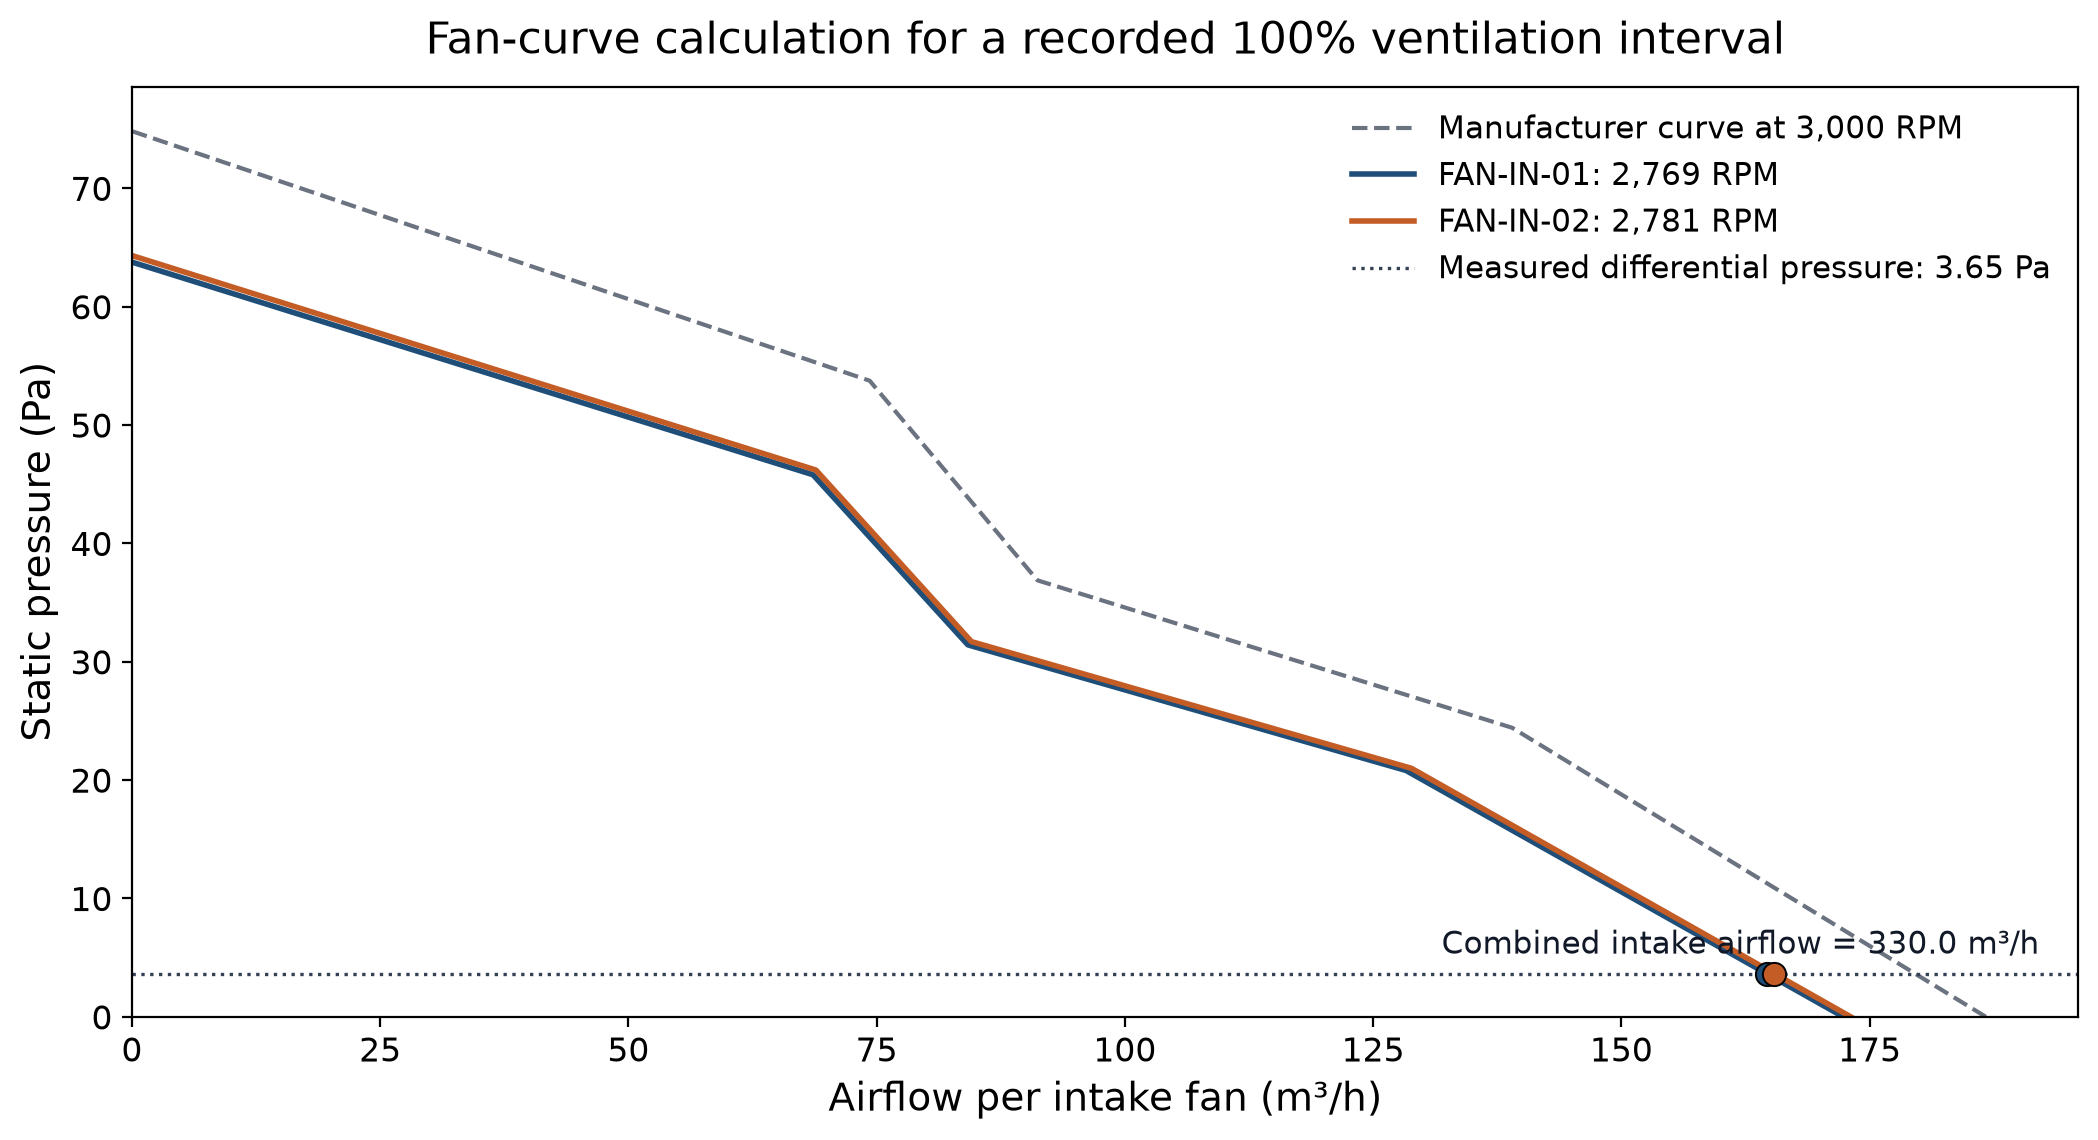

### Ventilation-effectiveness factor selection

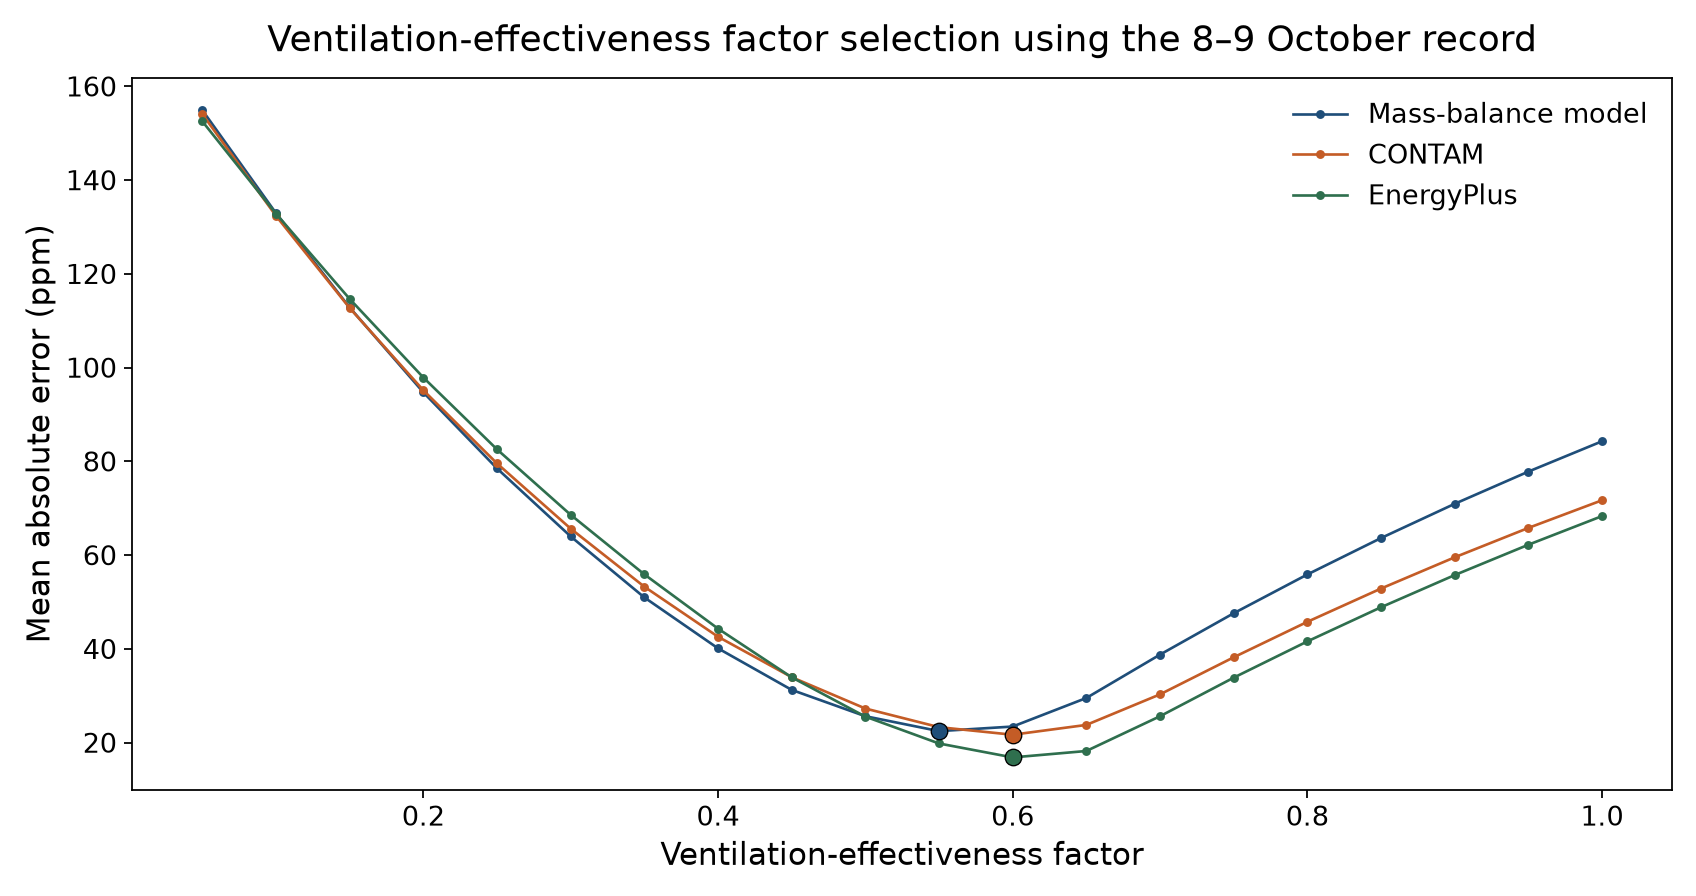

### Measured and predicted CO2

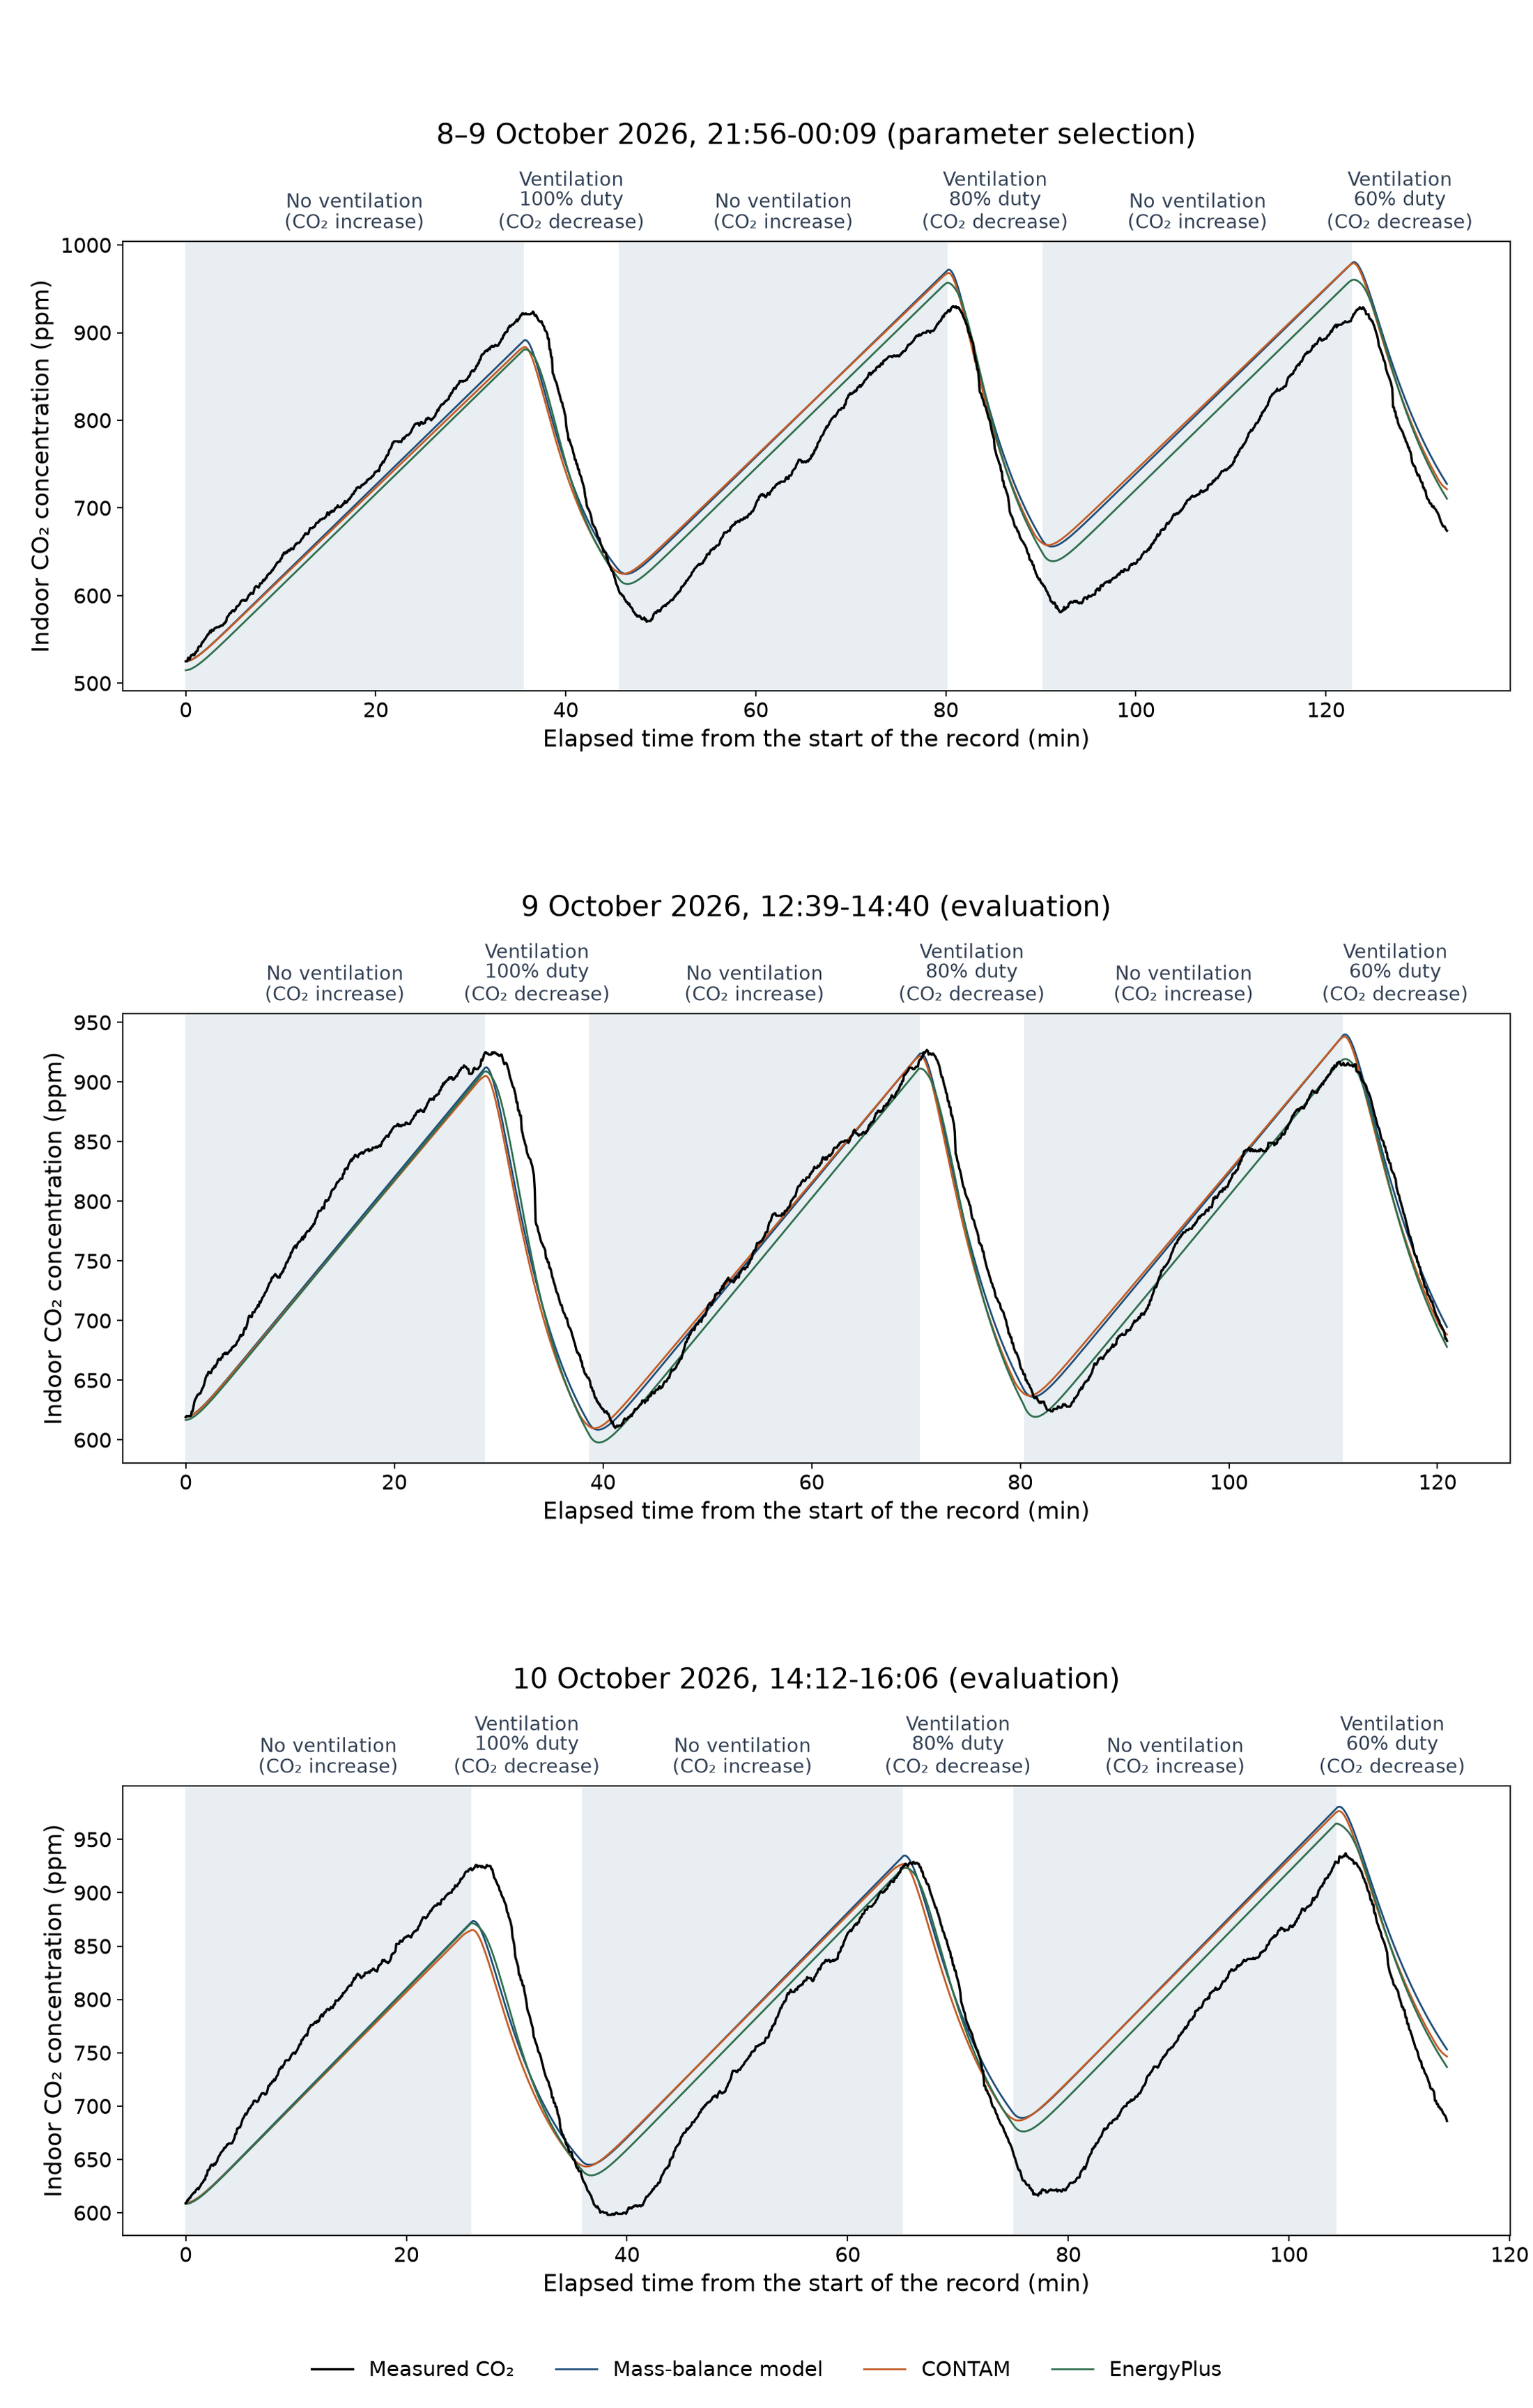

### Simulation error by record and ventilation state

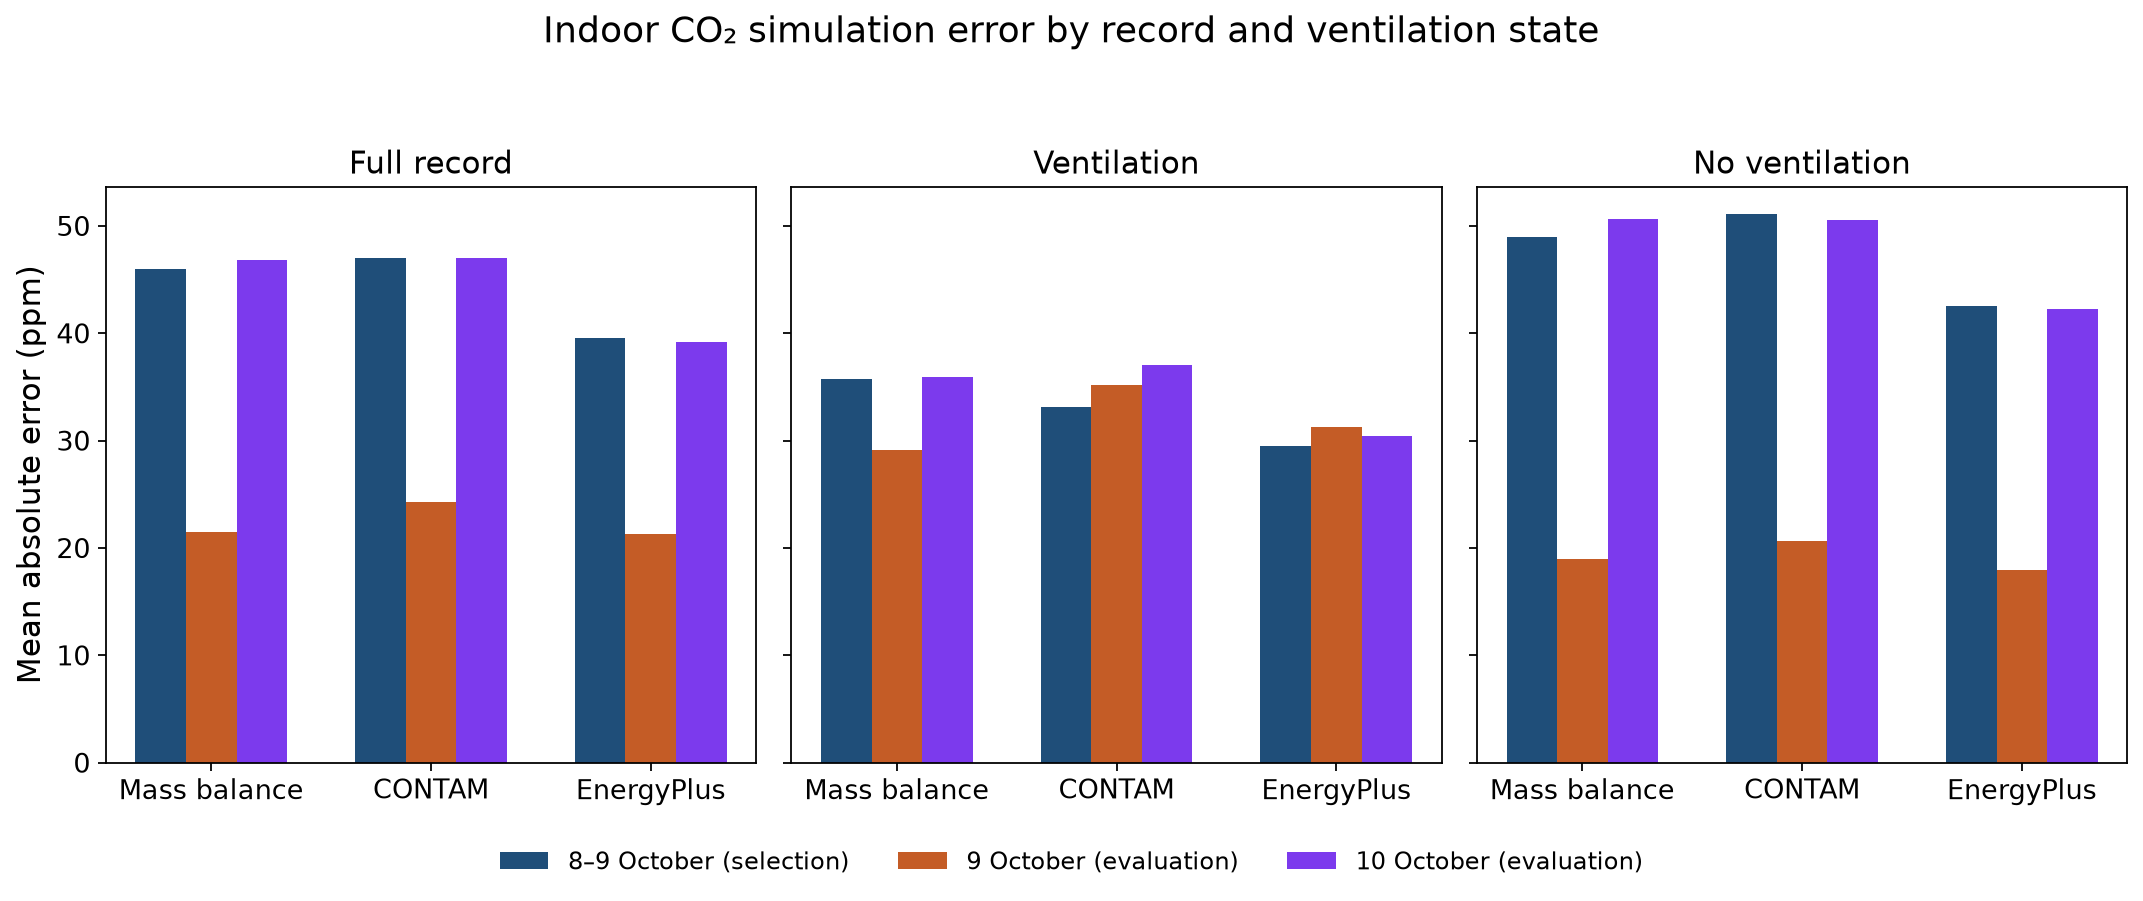

In [4]:
from indoortwin.evidence import display_plots
display_plots("05")
